# Speed & Accuracy analysis of `thermal_PhaseCurve()`

The runtime is almost entirely the single SPIDERMAN `lightcurve(t)` call (~99% at defaults). Only two knobs matter:
- **`N_LAYERS`** — the SPIDERMAN radial resolution; scales roughly **quadratically**. By far the biggest lever.
- **`len(t)`** — number of time samples; scales **linearly**.

Everything that builds the temperature map (`n_lo`, `n_la`, `insolation_model`, penumbra `order`) is a <1% preamble, and `filter` / `include_transit` / `include_occultation` are within noise.

In [1]:
import time, os
import contextlib, io
import numpy as np
import matplotlib.pyplot as plt
import spiderman as sp_old # standard spiderman
import fspiderman as sp # faster spiderman with c patches
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
import astro_utils, batman_utils
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
from joblib import Parallel, delayed
from simple_bias_analysis import FittingConfig, model_pcurve, fit_naive
from HItargets_utils import hi_planets_by_name
from paper_plot_utils import paper_figure, paper_theme


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("K2-141 b")
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = planet.args

u = [0.15, 0.08]
u_B = 0.6
A_B = 0.3

FILTER_DIR   = os.path.join(os.path.dirname(os.path.abspath('')), 'Filters', 'Spiderman')
lambda_range = 1e-6 * np.array([3.6955, 5.1008])                 # Spitzer/IRAC2
filter_path  = os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat")

def bench(fn, warmup=1, repeats=3):
    """Best-of-`repeats` wall time in milliseconds (warm-up excluded)."""
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * min(ts)

def time_tpc(**kw):
    """Time thermal_PhaseCurve with overrides on top of a hyper + filter baseline."""
    p = dict(u=u, u_B=u_B, A_B=A_B, filter_path=filter_path, insolation_model="hyperillum")
    p.update(kw)
    return bench(lambda: thermal_PhaseCurve(planet, lambda_range, **p))


# Config for the A_B-bias convergence section 6, reusing the Spitzer/IRAC2 setup above
l1, l2 = lambda_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=filter_path)
A_B_true = A_B
n_bins = 27 # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes] - approx. 15min
sigma_1min      = 323. # detection error [ppm per minute], MIRI/LRS 5.0-10.5 um
n_orbits        = 10 # number of orbits observed (3 orbits has been done)
cfg = FittingConfig(planet=planet, filter_path=filter_path, stellar_model="blackbody",   # blackbody star: the benchmark baseline; FittingConfig derives its stellar grid itself
                 l1=l1, l2=l2, A_=ConstantBandAlbedo(.1),
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=False, u_B=u_B, u=u)   # thermal-only phase curve; bounds=(0.0, 0.6) by default

no stellar models provided, using blackbody approximation


## 1. Where does the time go?  (stage decomposition)

The body of `thermal_PhaseCurve` on the exact path (`spman="normal"`) is replicated below with a timer around each stage (`decompose` defaults: hyperillum, filter, `N_LAYERS=60`, `n_lo=200`, `n_la=100`, `t=1000`). `thermal_PhaseCurve` itself now defaults to `spman="fast"` and to `N_LAYERS=40` for hyperillum (80 for naive), so its runtime split differs; see the `fast_lightcurve` section below.

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
total ~ 1989 ms

  MAIN lightcurve (SPIDERMAN, t=1000)                1926.2 ms  (96.85%)
  build temperature map (custom_temperature_grid)      42.3 ms  ( 2.12%)
  occultation depth (2x lightcurve @ 1 pt)             15.0 ms  ( 0.75%)
  stellar grid (gen_grid)                               3.1 ms  ( 0.15%)
  format_grid                                           2.3 ms  ( 0.12%)
  transit (batman)                                      0.1 ms  ( 0.00%)


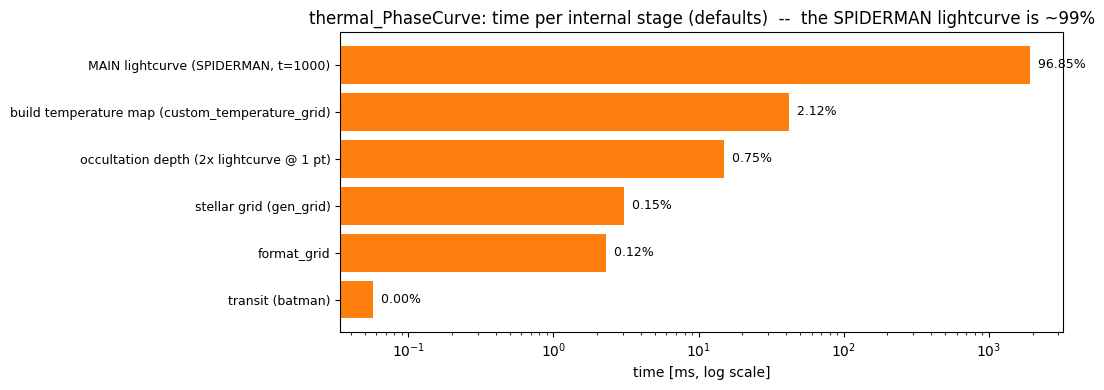

In [3]:
PAPER_MODE = False
def decompose(n_lo=200, n_la=100, N_LAYERS=60, model="hyperillum", fpath=filter_path, ntime=1000):
    T = {}
    t0=time.perf_counter(); lo,la,tg = custom_temperature_grid(planet, u_B=u_B, n_lo=n_lo, n_la=n_la, insolation_model=model, A_B=A_B); T["build temperature map (custom_temperature_grid)"]=time.perf_counter()-t0
    t0=time.perf_counter(); LO,LA=np.meshgrid(lo,la,indexing='ij'); grid=sp.format_grid(LO,LA,np.maximum(tg,100.).T); T["format_grid"]=time.perf_counter()-t0
    p=sp.ModelParams(brightness_model="direct_T", stellar_model="blackbody"); p.n_layers=N_LAYERS
    p.t0,p.per=0.,period; p.a_abs=a_AU; p.inc,p.ecc,p.w=incl,ecc,w; p.rp,p.a=rp,a; p.p_u1=p.p_u2=0.
    p.T_s=T_eff; p.grid=grid; p.l1,p.l2=lambda_range; p.filter=fpath
    t0=time.perf_counter(); sg=sp.stellar_grid.gen_grid(p.l1,p.l2,logg=4.5,response=p.filter,stellar_model="blackbody"); T["stellar grid (gen_grid)"]=time.perf_counter()-t0
    tocc=astro_utils.occultation_time(period, ecc, w, t0=0.)
    t0=time.perf_counter(); p.eclipse=False; p.lightcurve([tocc],stellar_grid=sg); p.eclipse=True; p.lightcurve([tocc],stellar_grid=sg); T["occultation depth (2x lightcurve @ 1 pt)"]=time.perf_counter()-t0
    tt=np.linspace(0.,period,ntime)
    t0=time.perf_counter(); p.lightcurve(tt,stellar_grid=sg); T["MAIN lightcurve (SPIDERMAN, t=%d)"%ntime]=time.perf_counter()-t0
    t0=time.perf_counter(); batman_utils.flux_transit(planet,tt,t0=0.,u=u); T["transit (batman)"]=time.perf_counter()-t0
    return T

decompose() # warm-up
D = decompose()
tot = sum(D.values())
ks = sorted(D, key=lambda k: D[k])
print(f"total ~ {tot*1e3:.0f} ms\n")
for k in reversed(ks):
    print(f"  {k:48s} {D[k]*1e3:8.1f} ms  ({100*D[k]/tot:5.2f}%)")

fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(range(len(ks)), [D[k]*1e3 for k in ks], color="C1")
ax.set_yticks(range(len(ks))); ax.set_yticklabels(ks, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("time [ms, log scale]")
ax.set_title("thermal_PhaseCurve: time per internal stage (defaults)  --  the SPIDERMAN lightcurve is ~99%")
for i, k in enumerate(ks): ax.text(D[k]*1e3, i, f"  {100*D[k]/tot:.2f}%", va="center", fontsize=9)
plt.tight_layout(); paper_figure("speed_stage_breakdown", PAPER_MODE); plt.show()

## 2. `N_LAYERS` -- the dominant cost (roughly quadratic; the fitted exponent is printed below)

`N_LAYERS` sets SPIDERMAN's radial discretization of the planet disk (segments ~ `N_LAYERS`²), so it drives the one expensive call. Swept at a fixed modest `t=300` to isolate it.

  N_LAYERS=  50:    126.7 ms
  N_LAYERS= 100:    166.3 ms
  N_LAYERS= 200:   1047.4 ms
  N_LAYERS= 500:   3186.5 ms
  N_LAYERS=1000:  10876.0 ms
  N_LAYERS=2000:  66111.9 ms

power-law exponent (N_LAYERS>=20): 1.71   (2.0 = perfectly quadratic)


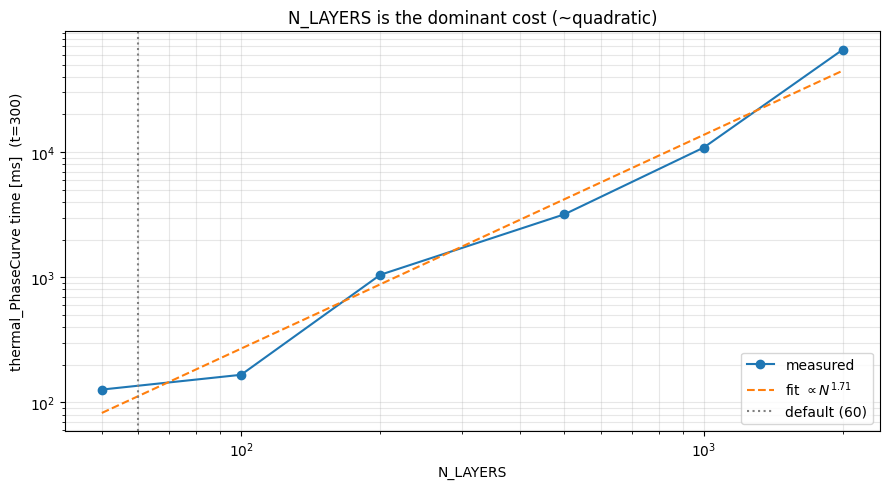

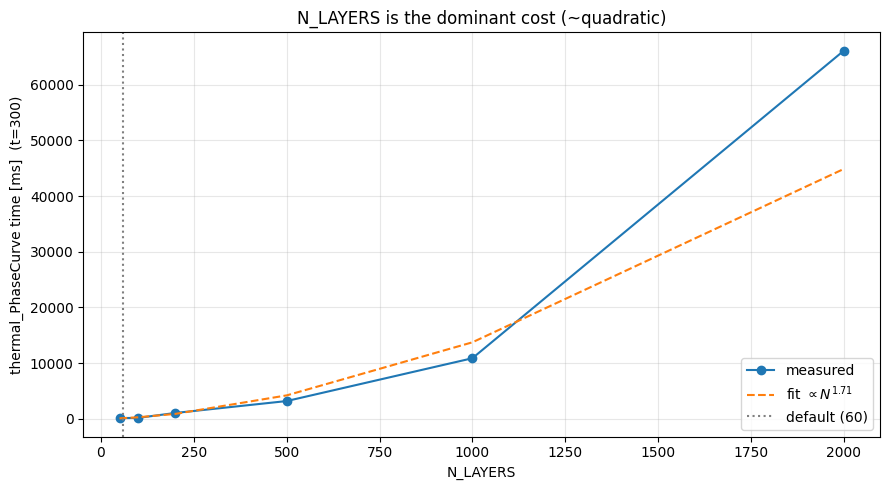

In [4]:
PAPER_MODE = False
NL_vals = [50, 100, 200, 500, 1000, 2000]
t_grid  = np.linspace(0., period, 300)
NL_times = [time_tpc(N_LAYERS=nl, t=t_grid) for nl in NL_vals]
for nl, ms in zip(NL_vals, NL_times): print(f"  N_LAYERS={nl:4d}: {ms:8.1f} ms")

NLa = np.array(NL_vals, float); msa = np.array(NL_times); sel = NLa >= 20
slope, intc = np.polyfit(np.log(NLa[sel]), np.log(msa[sel]), 1)
print(f"\npower-law exponent (N_LAYERS>=20): {slope:.2f}   (2.0 = perfectly quadratic)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(NL_vals, NL_times, "o-", label="measured")
ax.loglog(NLa[sel], np.exp(intc)*NLa[sel]**slope, "--", label=fr"fit $\propto N^{{{slope:.2f}}}$")
ax.axvline(60, color="grey", ls=":", label="default (60)")
ax.set_xlabel("N_LAYERS"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (t=300)")
ax.set_title("N_LAYERS is the dominant cost (~quadratic)"); ax.grid(which="both", alpha=.3); ax.legend()
plt.tight_layout(); paper_figure("speed_runtime_vs_nlayers_loglog", PAPER_MODE); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(NL_vals, NL_times, "o-", label="measured")
ax.plot(NLa[sel], np.exp(intc)*NLa[sel]**slope, "--", label=fr"fit $\propto N^{{{slope:.2f}}}$")
ax.axvline(60, color="grey", ls=":", label="default (60)")
ax.set_xlabel("N_LAYERS"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (t=300)")
ax.set_title("N_LAYERS is the dominant cost (~quadratic)"); ax.grid(which="both", alpha=.3); ax.legend()
plt.tight_layout(); paper_figure("speed_runtime_vs_nlayers_linear", PAPER_MODE); plt.show()

## 3. `len(t)` -- number of time samples (linear)

The lightcurve is evaluated point-by-point, so runtime is linear in `len(t)`. Swept at `N_LAYERS=30`.

  len(t)=  100:    120.9 ms
  len(t)=  300:    117.3 ms
  len(t)=  600:    136.8 ms
  len(t)= 1000:    125.3 ms
  len(t)= 2000:    161.7 ms
  len(t)= 4000:    282.8 ms


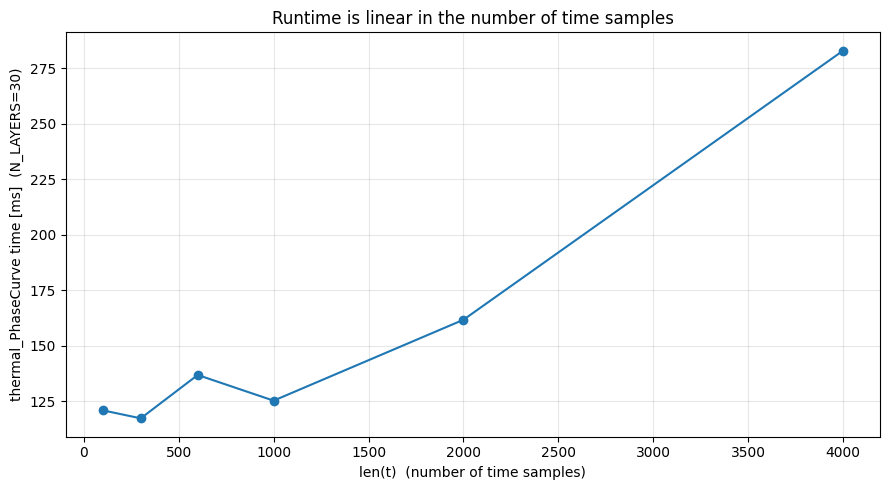

In [5]:
PAPER_MODE = False
nt_vals  = [100, 300, 600, 1000, 2000, 4000]
nt_times = [time_tpc(N_LAYERS=30, t=np.linspace(0., period, n)) for n in nt_vals]
for n, ms in zip(nt_vals, nt_times): print(f"  len(t)={n:5d}: {ms:8.1f} ms")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(nt_vals, nt_times, "o-")
ax.set_xlabel("len(t)  (number of time samples)"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (N_LAYERS=30)")
ax.set_title("Runtime is linear in the number of time samples"); ax.grid(alpha=.3)
plt.tight_layout(); paper_figure("speed_runtime_vs_nt", PAPER_MODE); plt.show()

## 4. Runtime: `Louden_PhaseCurve` vs `thermal_PhaseCurve(naive)`

  N_LAYERS=   4: thermal(naive) =     76.8 ms   Louden =     11.6 ms   speedup = 6.62x
  N_LAYERS=   8: thermal(naive) =    119.8 ms   Louden =     42.3 ms   speedup = 2.83x
  N_LAYERS=  16: thermal(naive) =     23.6 ms   Louden =     14.1 ms   speedup = 1.67x
  N_LAYERS=  30: thermal(naive) =    136.1 ms   Louden =     60.0 ms   speedup = 2.27x
  N_LAYERS=  45: thermal(naive) =    105.7 ms   Louden =     47.8 ms   speedup = 2.21x
  N_LAYERS=  60: thermal(naive) =    224.7 ms   Louden =    135.8 ms   speedup = 1.65x
  N_LAYERS=  90: thermal(naive) =    380.3 ms   Louden =    183.1 ms   speedup = 2.08x
  N_LAYERS= 120: thermal(naive) =    660.2 ms   Louden =    272.2 ms   speedup = 2.43x


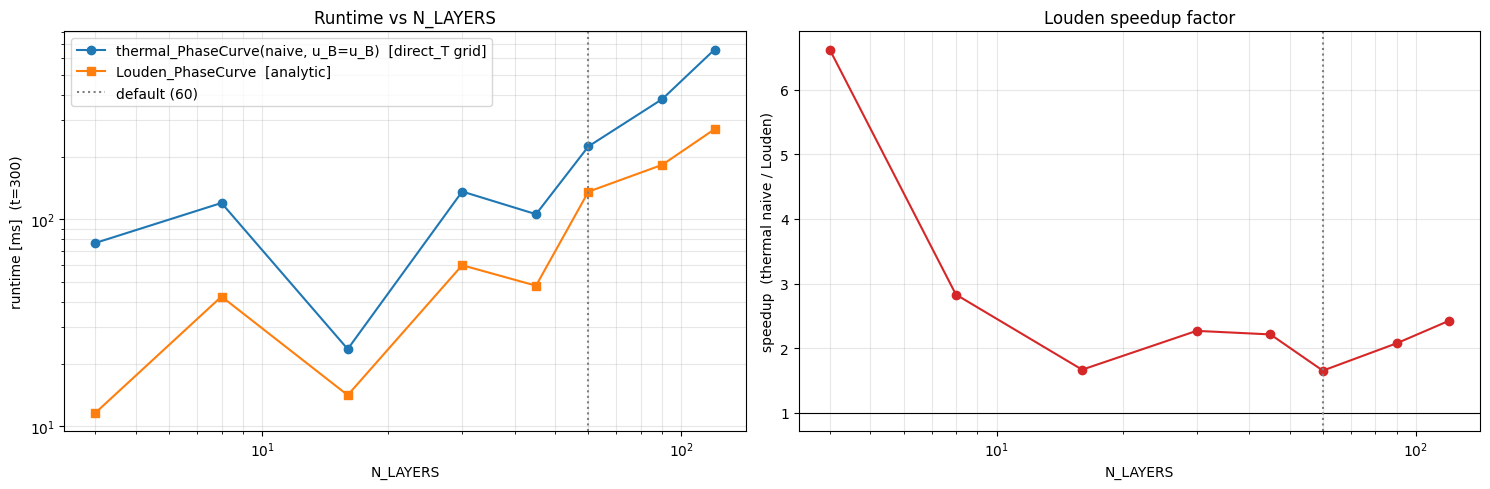

In [6]:
PAPER_MODE = False
NL_rt = [4, 8, 16, 30, 45, 60, 90, 120]
t_rt  = np.linspace(0., period, 300)
rt_naive  = [bench(lambda nl=nl: thermal_PhaseCurve(planet, lambda_range, t=t_rt, u=u, A_B=A_B,
                    filter_path=filter_path, insolation_model="naive", N_LAYERS=nl, u_B=u_B), repeats=2) for nl in NL_rt]
rt_louden = [bench(lambda nl=nl: Louden_PhaseCurve(planet, lambda_range, t=t_rt, A_B=A_B,
                    filter_path=filter_path, N_LAYERS=nl), repeats=2) for nl in NL_rt]
for nl, n, l in zip(NL_rt, rt_naive, rt_louden):
    print(f"  N_LAYERS={nl:4d}: thermal(naive) = {n:8.1f} ms   Louden = {l:8.1f} ms   speedup = {n/l:.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].loglog(NL_rt, rt_naive,  "o-", label="thermal_PhaseCurve(naive, u_B=u_B)  [direct_T grid]")
ax[0].loglog(NL_rt, rt_louden, "s-", label="Louden_PhaseCurve  [analytic]")
ax[0].axvline(60, color="grey", ls=":", label="default (60)")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("runtime [ms]  (t=300)")
ax[0].set_title("Runtime vs N_LAYERS"); ax[0].grid(which="both", alpha=.3); ax[0].legend()
ax[1].semilogx(NL_rt, np.array(rt_naive)/np.array(rt_louden), "o-", color="C3")
ax[1].axhline(1, color="k", lw=.8); ax[1].axvline(60, color="grey", ls=":")
ax[1].set_xlabel("N_LAYERS"); ax[1].set_ylabel("speedup  (thermal naive / Louden)")
ax[1].set_title("Louden speedup factor"); ax[1].grid(which="both", alpha=.3)
plt.tight_layout(); paper_figure("speed_runtime_louden_vs_nlayers", PAPER_MODE); plt.show()

## 5. Convergence with N_LAYERS

Here each illumination model's phase curve is compared against a high-resolution **ground truth** (`N_LAYERS = 240`) computed on the *same* time grid, so the curves differ only through `N_LAYERS`. The convergence metric is the **RMS deviation of the phase curve from the ground truth (ppm)**; the maximum pointwise deviation and the occultation-depth error $|f_p - f_p^{\rm GT}|$ are shown alongside.

ground truth: N_LAYERS = 240   (f_p [ppm]: naive = 165.77, hyperillum = 166.87, louden = 165.77)

  naive : RMS deviation ~ N_LAYERS^-1.64   (RMS ~ 0.027 ppm at default N=60)
  hyperillum: RMS deviation ~ N_LAYERS^-1.60   (RMS ~ 0.029 ppm at default N=60)
  louden: RMS deviation ~ N_LAYERS^-1.63   (RMS ~ 0.027 ppm at default N=60)


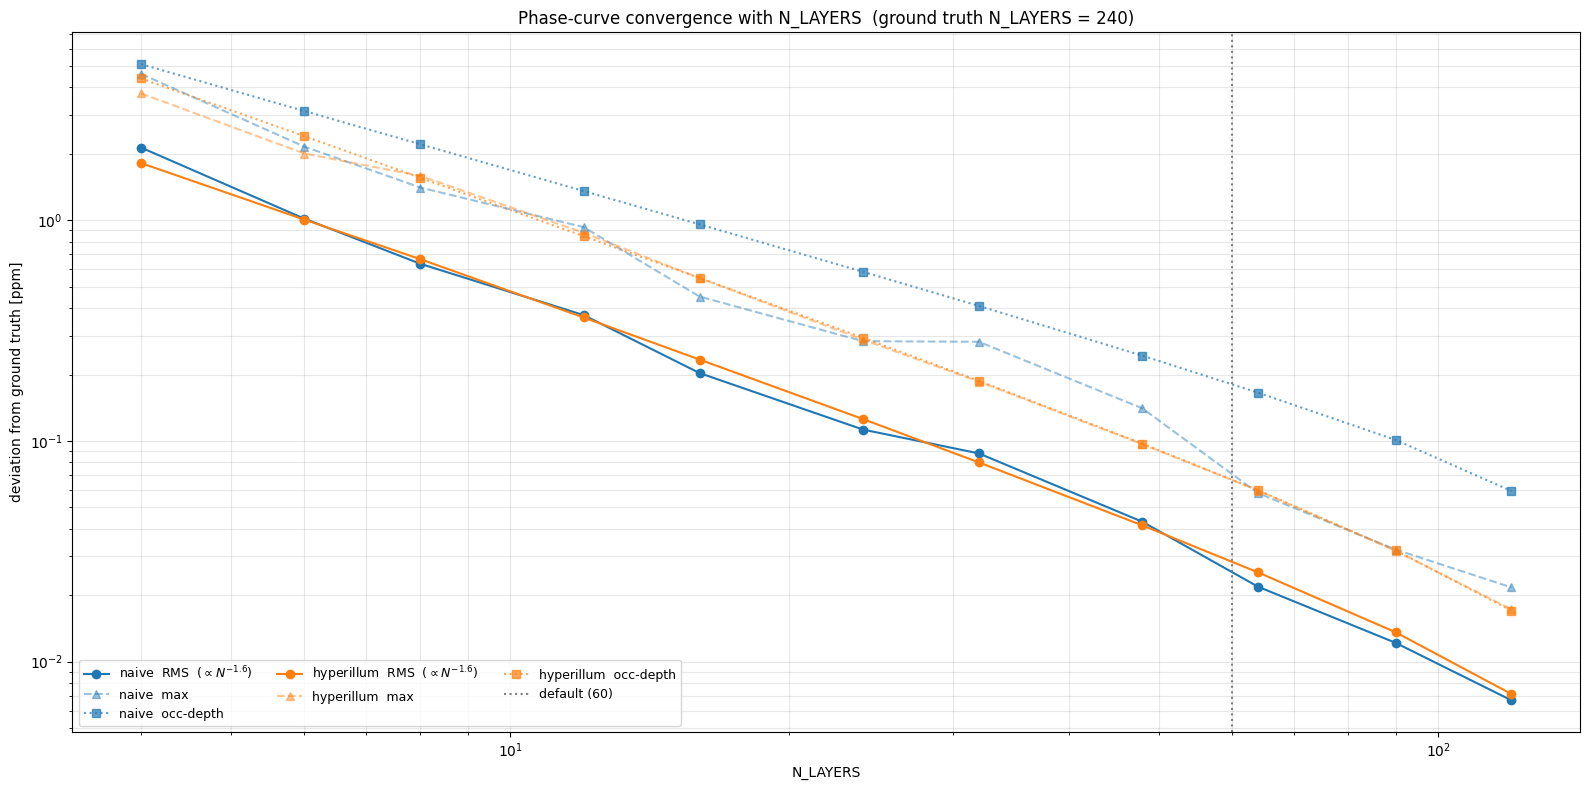

In [7]:
PAPER_MODE = False
# Convergence of the phase curve with N_LAYERS, vs a high-N_LAYERS ground truth, for all three models
t_conv  = np.linspace(0., period, 200)               # shared grid -> curves differ only through N_LAYERS
NL_GT   = 240                                        # ground-truth reference resolution
NL_conv = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 90, 120])

def _phasecurve(model, nl):
    if model == "louden":   # separate SPIDERMAN model (analytic F=0 map); u left at its default
        return Louden_PhaseCurve(planet, lambda_range, t=t_conv, A_B=A_B, filter_path=filter_path, N_LAYERS=nl)
    return thermal_PhaseCurve(planet, lambda_range, t=t_conv, u=u, A_B=A_B, filter_path=filter_path,
                              insolation_model=model, N_LAYERS=nl, u_B=u_B)

conv = {}
for model in ["naive", "hyperillum", "louden"]:
    _, pc_gt, fp_gt, _ = _phasecurve(model, NL_GT)
    rms, mx, fperr = [], [], []
    for nl in NL_conv:
        _, pc, fp, _ = _phasecurve(model, int(nl))
        d = (pc - pc_gt) * 1e6                        # pointwise deviation [ppm]
        rms.append(np.sqrt(np.mean(d**2))); mx.append(np.abs(d).max()); fperr.append(abs(fp - fp_gt))
    conv[model] = dict(rms=np.array(rms), mx=np.array(mx), fperr=np.array(fperr), fp_gt=fp_gt)

print(f"ground truth: N_LAYERS = {NL_GT}   (f_p [ppm]: " + ", ".join(f"{m} = {conv[m]['fp_gt']:.2f}" for m in conv) + ")\n")
rate = {}
for model in ["naive", "hyperillum", "louden"]:
    slope, _ = np.polyfit(np.log(NL_conv), np.log(conv[model]["rms"]), 1)
    rate[model] = -slope
    i60 = np.interp(60, NL_conv, conv[model]["rms"])
    print(f"  {model:6s}: RMS deviation ~ N_LAYERS^-{-slope:.2f}   (RMS ~ {i60:.3f} ppm at default N=60)")

plt.figure(figsize=(16, 8))
for model, c in [("naive", "C0"), ("hyperillum", "C1")]: # , ("louden", "C2")
    plt.loglog(NL_conv, conv[model]["rms"],   "o-",  color=c, label=fr"{model}  RMS  ($\propto N^{{-{rate[model]:.1f}}}$)")
    plt.loglog(NL_conv, conv[model]["mx"],    "^--", color=c, alpha=.45, label=f"{model}  max")
    plt.loglog(NL_conv, conv[model]["fperr"], "s:",  color=c, alpha=.7,  label=f"{model}  occ-depth")
plt.axvline(60, color="grey", ls=":", label="default (60)")
plt.xlabel("N_LAYERS"); plt.ylabel("deviation from ground truth [ppm]")
plt.title(f"Phase-curve convergence with N_LAYERS  (ground truth N_LAYERS = {NL_GT})")
plt.grid(which="both", alpha=.3); plt.legend(ncol=3, fontsize=9)
plt.tight_layout()
paper_figure("speed_convergence_nlayers", PAPER_MODE)
plt.show()

## 6. Bias convergence with N_LAYERS, len(t), ...

converged bias (n_layers=120, n_t=2000, grid=600x300, xatol=1e-4) = -0.0399

knob             swept range  bias span   Source
n_layers           20 -> 120     0.0001   disk shells
n_t               27 -> 2700     0.0121   time samples
n_lo               50 -> 600     0.0021   lon grid pts
xatol         0.03 -> 0.0001     0.0052   fit tolerance


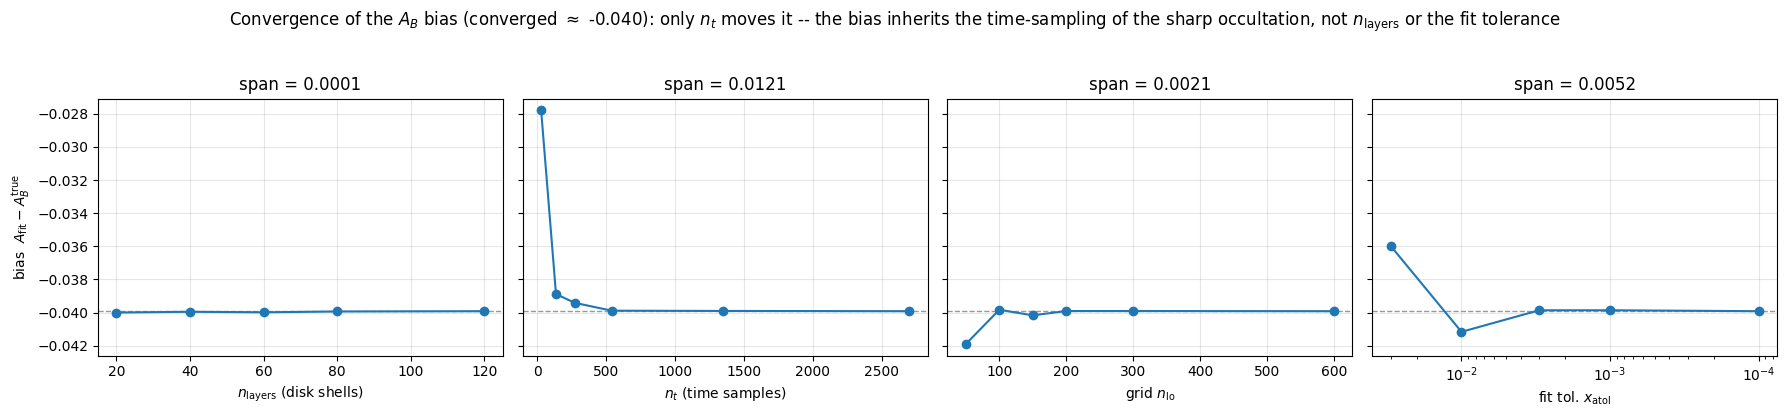

In [8]:
PAPER_MODE = False
REF  = dict(n_layers=120, n_t=100*n_bins, n_lo=600, n_la=300)   # converged reference
XREF = 1e-4                                              # tight fit tolerance

def conv_bias(xatol=XREF, **over):
    kw = {**REF, **over}
    _, tr    = model_pcurve(cfg, "hyperillum", A_B_true, **kw)
    A_fit, _, _ = fit_naive(cfg, tr, xatol=xatol, **kw)          # free_offset=True (default)
    return A_fit - A_B_true

# one knob varied per sweep
sweeps = {
    "n_layers": [dict(n_layers=v)            for v in (20, 40, 60, 80, 120)],
    "n_t":      [dict(n_t=v)                 for v in np.array([1, 5, 10, 20, 50, 100])*n_bins],
    "n_lo":     [dict(n_lo=v, n_la=v // 2)   for v in (50, 100, 150, 200, 300, 600)],
    "xatol":    [dict(xatol=v)               for v in (3e-2, 1e-2, 3e-3, 1e-3, 1e-4)],
}
key_of = {"n_layers": "n_layers", "n_t": "n_t", "n_lo": "n_lo", "xatol": "xatol"}
flat   = [(name, over) for name, lst in sweeps.items() for over in lst]

vals = Parallel(n_jobs=-1, backend="loky")(delayed(conv_bias)(**over) for _, over in flat)
get_reusable_executor().shutdown(wait=True)  # free the memory SPIDERMAN leaks in the workers

results = {name: [] for name in sweeps}
for (name, over), b in zip(flat, vals):
    x = over.get(key_of[name], REF.get(key_of[name], XREF))
    results[name].append((x, b))

bias_ref = dict(results["n_t"])[REF["n_t"]]              # bias at the reference config
print(f"converged bias (n_layers=120, n_t=2000, grid=600x300, xatol=1e-4) = {bias_ref:+.4f}\n")
print(f"{'knob':9s} {'swept range':>18s} {'bias span':>10s}   Source")
labels = {"n_layers":"disk shells","n_t":"time samples","n_lo":"lon grid pts","xatol":"fit tolerance"}
for name in sweeps:
    xs = [x for x, _ in results[name]]; ys = [b for _, b in results[name]]
    span = max(ys) - min(ys)
    rng  = f"{xs[0]:g} -> {xs[-1]:g}"
    print(f"{name:9s} {rng:>18s} {span:>10.4f}   {labels[name]}")

# the variation lives almost entirely in n_t; n_layers / grid / fit-tol are flat
panels = [("n_layers", r"$n_\mathrm{layers}$ (disk shells)", False),
          ("n_t",      r"$n_t$ (time samples)",              False),
          ("n_lo",     r"grid $n_\mathrm{lo}$",              False),
          ("xatol",    r"fit tol. $x_\mathrm{atol}$",        True)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, xlabel, logx) in zip(axes, panels):
    xs = [x for x, _ in results[name]]; ys = [b for _, b in results[name]]
    ax.axhline(bias_ref, color="0.6", ls="--", lw=1, zorder=1)
    ax.plot(xs, ys, "-o", color="C0", lw=1.5, ms=6, zorder=2)
    if logx: ax.set_xscale("log"); ax.invert_xaxis()    # tighter tolerance -> right
    ax.set_xlabel(xlabel); ax.grid(alpha=.3)
    ax.set_title(f"span = {max(ys) - min(ys):.4f}")
axes[0].set_ylabel(r"bias  $A_\mathrm{fit}-A_B^\mathrm{true}$")
fig.suptitle(rf"Convergence of the $A_B$ bias (converged $\approx$ {bias_ref:+.3f}): "
             r"only $n_t$ moves it -- the bias inherits the time-sampling of the sharp "
             r"occultation, not $n_\mathrm{layers}$ or the fit tolerance", y=1.03)
fig.tight_layout()
paper_figure("speed_bias_convergence", PAPER_MODE, fig=fig)
plt.show()

# SPIDERMAN Speedup

## 1. SPIDERMAN fast_lightcurve (interpolated) vs lightcurve (exact)

`thermal_PhaseCurve(..., spman=..., spman_kw=...)` chooses how the SPIDERMAN phase modulation + occultation is evaluated:

- **`"normal"`** calls `spider_params.lightcurve(t)` at *every* one of the `len(t)` time samples (exact).
- **`"fast"`** uses `fast_lightcurve`, which splits the orbit into three regimes:
  - *out of occultation* — the smooth, band-limited phase modulation is trigonometrically interpolated from just **`n_phase=40`** uniform nodes (24 in `model_pcurve`);
  - *ingress / egress ramps* — kinks and steep contact points, evaluated **exactly** (both ramps in a single `lightcurve()` call);
  - *totality* — the planet is fully behind the star, so there is no planetary flux and the light curve is **exactly** the (normalised) stellar flux; set to 1 with **no SPIDERMAN call at all**.

Cost therefore drops from `len(t)` evaluations to `n_phase + (points inside the two ramps)`. For K2-141b the padded occultation window is 15.4% of the orbit but the two ramps are only 2×1.19% of it (K2-141 b, `pad=0.03`), so the occultation — which used to dominate `fast` — almost disappears.

Because the totality value is exact rather than approximated (asserted below), `spman="fast"` is **bit-identical** to the previous whole-window version, which is still reachable as `spman_kw=dict(split_totality=False)`. Every accuracy number in this section is therefore unchanged by the split; only the runtime moves. `spman_kw` is forwarded by `full_PhaseCurve`, `thermal_PhaseCurve`, `Louden_PhaseCurve` and `model_pcurve`, and overrides `fast_lightcurve`'s `n_phase` / `pad` / `split_totality`.

hyperillum N_LAYERS=60, len(t)=1000:  max|Δ| = 0.0030 ppm, rms = 0.0005 ppm,  fp fast/normal = 166.936/166.936 ppm  |  SPIDERMAN evals 1000 -> 40+154 (no split) -> 40+24 (split)  |  split == no-split bit-for-bit: True
naive      N_LAYERS=60, len(t)=1000:  max|Δ| = 0.0714 ppm, rms = 0.0102 ppm,  fp fast/normal = 165.949/165.949 ppm  |  SPIDERMAN evals 1000 -> 40+154 (no split) -> 40+24 (split)  |  split == no-split bit-for-bit: True


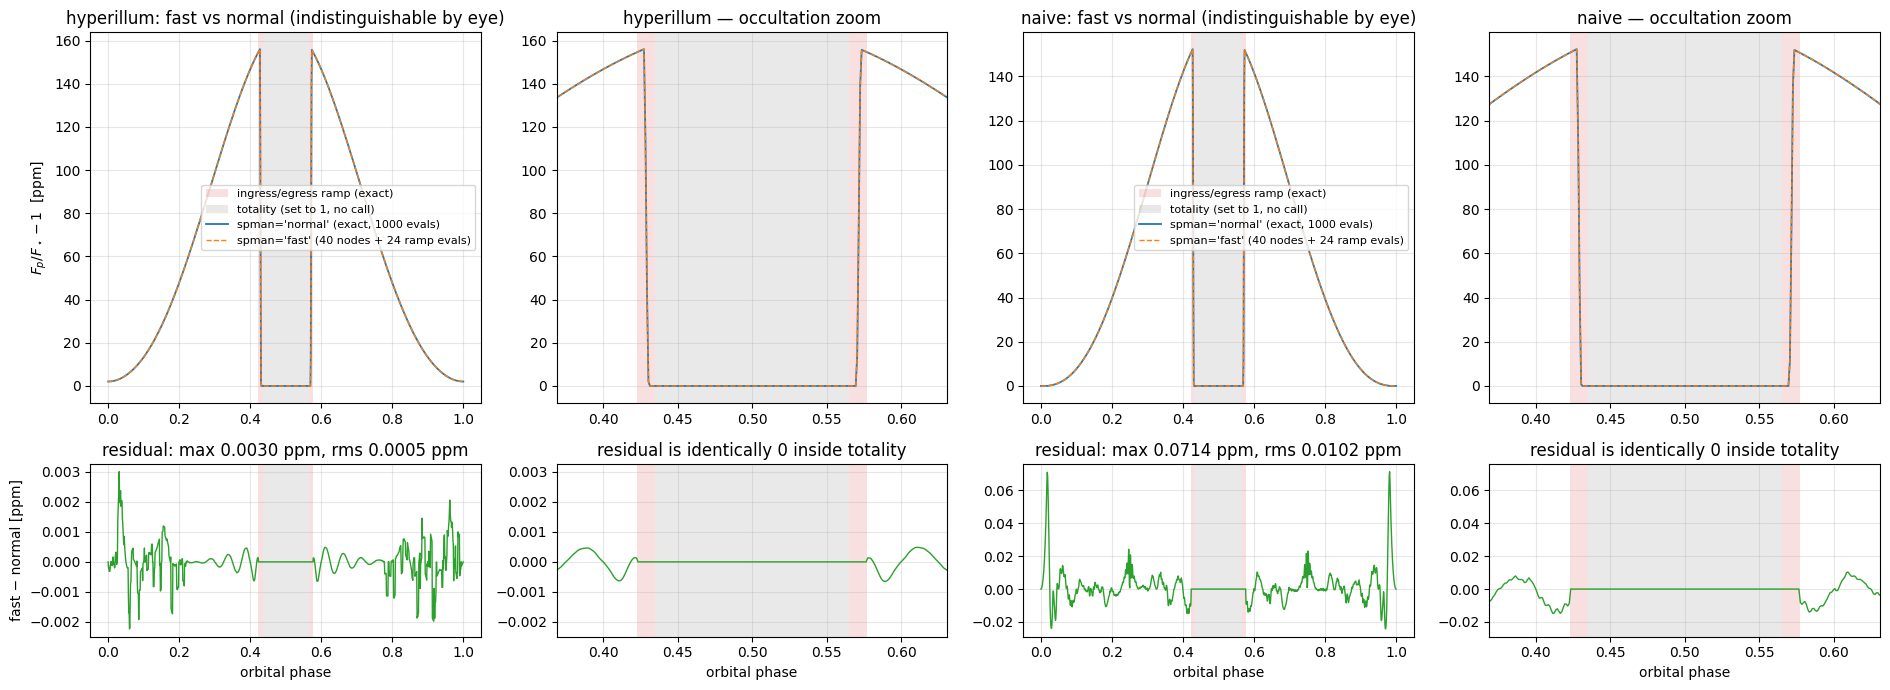

In [9]:
PAPER_MODE = False
from hyperillumination_phasecurve_utils import occultation_window, occultation_durations

# reference config: overlay fast vs normal and show the residual, for BOTH illumination models
N_LAYERS, N, PAD = 60, 1000, 0.03   # PAD must match fast_lightcurve's `pad`: it sets both the shading below and the totality the split skips
tt = np.linspace(0., period, N)

def tpc(model, **kw):
    return thermal_PhaseCurve(planet, lambda_range, t=tt, u=u, A_B=A_B, filter_path=filter_path,
                              N_LAYERS=N_LAYERS, insolation_model=model, include_transit=False, u_B=u_B, **kw)

fig, ax = plt.subplots(2, 4, figsize=(19, 7), gridspec_kw=dict(height_ratios=[3, 1.4]))
for j, model in enumerate(("hyperillum", "naive")):
    _, pc_norm,  fp_norm, sp_n = tpc(model, spman="normal")
    _, pc_fast,  fp_fast, _    = tpc(model, spman="fast")
    _, pc_whole, _,       _    = tpc(model, spman="fast", spman_kw=dict(split_totality=False))  # pre-split behaviour: whole padded window exact
    resid = (pc_fast - pc_norm) * 1e6                    # ppm

    t_in, t_out = occultation_window(sp_n, pad=PAD)
    T14, T23    = occultation_durations(sp_n)
    t_occ, half_tot = 0.5 * (t_in + t_out), 0.5 * T23 - PAD * T14   # the totality half-width fast_lightcurve actually skips
    n_ramp = int(((tt >= t_in) & (tt <= t_out) & (np.abs(tt - t_occ) >= half_tot)).sum())
    n_win  = int(((tt >= t_in) & (tt <= t_out)).sum())
    print(f"{model:10s} N_LAYERS={N_LAYERS}, len(t)={N}:  max|Δ| = {np.abs(resid).max():.4f} ppm, rms = {np.sqrt((resid**2).mean()):.4f} ppm,  "
          f"fp fast/normal = {fp_fast:.3f}/{fp_norm:.3f} ppm  |  SPIDERMAN evals {N} -> 40+{n_win} (no split) -> 40+{n_ramp} (split)  |  "
          f"split == no-split bit-for-bit: {np.array_equal(pc_fast, pc_whole)}")

    # three shaded regimes; drawn on the full-orbit column AND the zoom column
    bands = [(t_in, t_occ - half_tot, "C3", "ingress/egress ramp (exact)"), (t_occ + half_tot, t_out, "C3", None),
             (t_occ - half_tot, t_occ + half_tot, "0.4", "totality (set to 1, no call)")]
    for col, zoom in ((2 * j, False), (2 * j + 1, True)):
        for row in (0, 1):
            for lo, hi, c, lab in bands:
                ax[row, col].axvspan(lo / period, hi / period, color=c, alpha=.14, lw=0, label=lab if row == 0 else None)
            ax[row, col].grid(alpha=.3)
            if zoom: ax[row, col].set_xlim((t_in - 0.35 * (t_out - t_in)) / period, (t_out + 0.35 * (t_out - t_in)) / period)
        ax[0, col].plot(tt / period, pc_norm * 1e6, color="C0", lw=1.3, label=f"spman='normal' (exact, {N} evals)")
        ax[0, col].plot(tt / period, pc_fast * 1e6, color="C1", lw=1.0, ls="--", label=f"spman='fast' (40 nodes + {n_ramp} ramp evals)")
        ax[1, col].plot(tt / period, resid, color="C2", lw=1)
        ax[1, col].set_xlabel("orbital phase")
        ax[0, col].set_title(f"{model}{' — occultation zoom' if zoom else ': fast vs normal (indistinguishable by eye)'}")
        ax[1, col].set_title(f"residual: max {np.abs(resid).max():.4f} ppm, rms {np.sqrt((resid**2).mean()):.4f} ppm" if not zoom
                             else "residual is identically 0 inside totality")
    ax[0, 2 * j].legend(fontsize=8)
ax[0, 0].set_ylabel(r"$F_p/F_\star - 1$  [ppm]")
ax[1, 0].set_ylabel("fast − normal [ppm]")
plt.tight_layout(); paper_figure("speed_fast_vs_normal", PAPER_MODE); plt.show()

In [10]:
# The premise of the ramp/totality/ramp split: while the planet is fully behind the star there is no planetary flux,
# so SPIDERMAN returns EXACTLY the (normalised) stellar flux and fast_lightcurve can set out[totality] = 1 without calling it.
from hyperillumination_phasecurve_utils import occultation_durations
t_occ = astro_utils.occultation_time(period, ecc, w, t0=0.)
print(f"{'model':12s}{'N_LAYERS':>9s}   flux - 1  at [totality centre, 2nd contact + pad*T14, 3rd contact − pad*T14]")
for model in ("hyperillum", "naive"):
    for NL in (16, 60, 120):
        *_, p = thermal_PhaseCurve(planet, lambda_range, t=np.array([0.]), u=u, A_B=A_B, filter_path=filter_path,
                                   N_LAYERS=NL, insolation_model=model, include_transit=False, u_B=u_B)
        T14, T23 = occultation_durations(p)
        p.eclipse = True
        f = p.lightcurve(np.array([t_occ, t_occ - 0.5 * T23 + 0.03 * T14, t_occ + 0.5 * T23 - 0.03 * T14]), stellar_grid=stellar_grid) - 1.
        print(f"  {model:10s}{NL:9d}   {['%.3e' % v for v in f]}")
        assert np.all(f == 0.), f"totality is not exactly the stellar flux ({model}, N_LAYERS={NL}) -> split_totality would be an approximation"
print("\nexactly 0 everywhere -> out[totality] = 1. is exact, so spman='fast' is bit-identical to the pre-split whole-window version.")

model        N_LAYERS   flux - 1  at [totality centre, 2nd contact + pad*T14, 3rd contact − pad*T14]
  hyperillum       16   ['0.000e+00', '0.000e+00', '0.000e+00']
  hyperillum       60   ['0.000e+00', '0.000e+00', '0.000e+00']
  hyperillum      120   ['0.000e+00', '0.000e+00', '0.000e+00']
  naive            16   ['0.000e+00', '0.000e+00', '0.000e+00']
  naive            60   ['0.000e+00', '0.000e+00', '0.000e+00']
  naive           120   ['0.000e+00', '0.000e+00', '0.000e+00']

exactly 0 everywhere -> out[totality] = 1. is exact, so spman='fast' is bit-identical to the pre-split whole-window version.


split_totality bit-identical at all 22 configurations (assert above never fired)


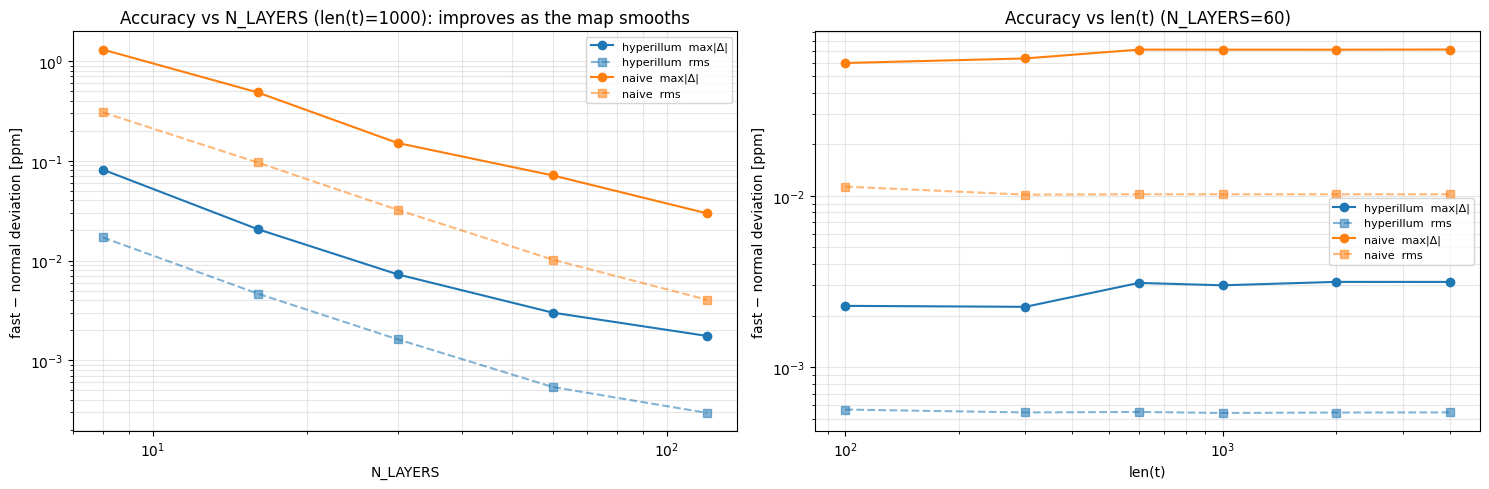

In [11]:
PAPER_MODE = False
# accuracy of 'fast' vs 'normal' as a function of N_LAYERS and len(t), for both illumination models.
# The third call re-runs 'fast' with the totality split OFF: the split must not move a single bit, only the runtime.
def spman_accuracy(NL, N, model):
    t_ = np.linspace(0., period, N)
    def tpc(**kw): return thermal_PhaseCurve(planet, lambda_range, t=t_, u=u, A_B=A_B, filter_path=filter_path,
                                             N_LAYERS=NL, insolation_model=model, include_transit=False, u_B=u_B, **kw)[1]
    pn, pf, pw = tpc(spman="normal"), tpc(spman="fast"), tpc(spman="fast", spman_kw=dict(split_totality=False))
    assert np.array_equal(pf, pw), f"split_totality changed the result at N_LAYERS={NL}, len(t)={N}, {model}"
    d = np.abs(pf - pn) * 1e6
    return d.max(), np.sqrt((d ** 2).mean())

NL_vals = [8, 16, 30, 60, 120]
nt_vals = [100, 300, 600, 1000, 2000, 4000]
acc_NL = {m: np.array([spman_accuracy(NL, 1000, m) for NL in NL_vals]) for m in ("hyperillum", "naive")}   # rows: [max|Δ|, rms]
acc_nt = {m: np.array([spman_accuracy(60, N, m) for N in nt_vals]) for m in ("hyperillum", "naive")}
print(f"split_totality bit-identical at all {2 * (len(NL_vals) + len(nt_vals))} configurations (assert above never fired)")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for m, c in (("hyperillum", "C0"), ("naive", "C1")):
    # left: vs N_LAYERS -- deviation falls as the disk map (and thus the phase modulation) smooths
    ax[0].loglog(NL_vals, acc_NL[m][:, 0], "o-",  color=c, label=f"{m}  max|Δ|")
    ax[0].loglog(NL_vals, acc_NL[m][:, 1], "s--", color=c, alpha=.55, label=f"{m}  rms")
    # right: vs len(t) -- flat (the interpolation error is a function of orbital phase, not sampling)
    ax[1].loglog(nt_vals, acc_nt[m][:, 0], "o-",  color=c, label=f"{m}  max|Δ|")
    ax[1].loglog(nt_vals, acc_nt[m][:, 1], "s--", color=c, alpha=.55, label=f"{m}  rms")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("fast − normal deviation [ppm]")
ax[0].set_title("Accuracy vs N_LAYERS (len(t)=1000): improves as the map smooths")
ax[0].grid(which="both", alpha=.3); ax[0].legend(fontsize=8)
ax[1].set_xlabel("len(t)"); ax[1].set_ylabel("fast − normal deviation [ppm]")
ax[1].set_title("Accuracy vs len(t) (N_LAYERS=60)")
ax[1].grid(which="both", alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); paper_figure("speed_fast_accuracy", PAPER_MODE); plt.show()

  len(t)=  100:  normal =    401.4 ms   fast/no split =   108.4 ms ( 3.70x)   fast =   123.0 ms ( 3.26x vs normal,  0.88x vs no split)
  len(t)=  300:  normal =    894.1 ms   fast/no split =   165.7 ms ( 5.40x)   fast =   118.2 ms ( 7.57x vs normal,  1.40x vs no split)
  len(t)=  600:  normal =   1368.4 ms   fast/no split =   226.6 ms ( 6.04x)   fast =   126.7 ms (10.80x vs normal,  1.79x vs no split)
  len(t)= 1000:  normal =   2276.3 ms   fast/no split =   302.3 ms ( 7.53x)   fast =   144.1 ms (15.80x vs normal,  2.10x vs no split)
  len(t)= 2000:  normal =   4492.6 ms   fast/no split =   488.7 ms ( 9.19x)   fast =   178.2 ms (25.21x vs normal,  2.74x vs no split)
  len(t)= 4000:  normal =   8004.2 ms   fast/no split =   861.8 ms ( 9.29x)   fast =   212.3 ms (37.70x vs normal,  4.06x vs no split)
  len(t)= 8000:  normal =   8437.7 ms   fast/no split =  1612.2 ms ( 5.23x)   fast =   310.0 ms (27.21x vs normal,  5.20x vs no split)


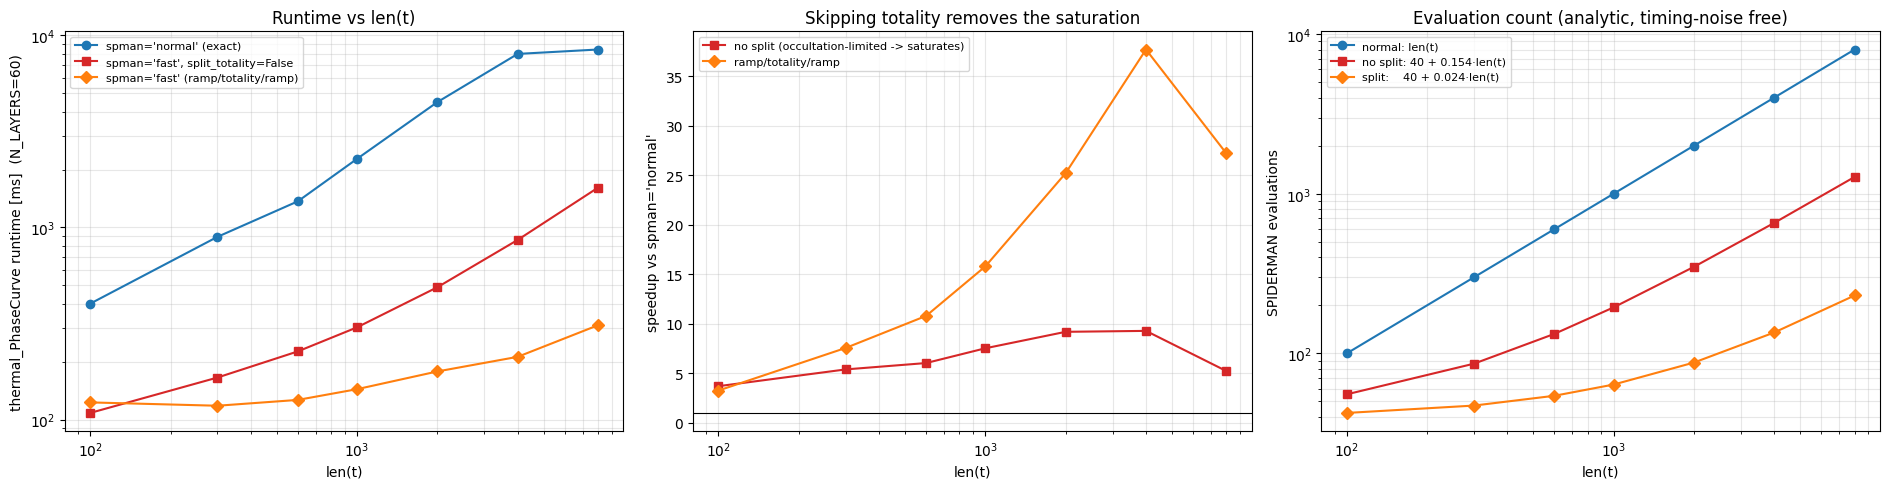

In [12]:
PAPER_MODE = False
# runtime vs len(t). 'normal' evaluates all len(t). 'fast (no split)' evaluates 40 nodes + the WHOLE padded occultation window (the pre-split behaviour,
# occultation-limited -> saturates). 'fast' evaluates 40 nodes + only the two ingress/egress ramps. The temperature-grid build + fp overhead is common to all three.
nt_vals = [100, 300, 600, 1000, 2000, 4000, 8000]
def spman_runtime(spman, N, **kw):
    t_ = np.linspace(0., period, N)
    return bench(lambda: thermal_PhaseCurve(planet, lambda_range, t=t_, u=u, A_B=A_B, filter_path=filter_path,
                                            N_LAYERS=60, insolation_model="hyperillum", include_transit=False, spman=spman, u_B=u_B, **kw), repeats=2)
rt_norm  = [spman_runtime("normal", N) for N in nt_vals]
rt_whole = [spman_runtime("fast", N, spman_kw=dict(split_totality=False)) for N in nt_vals]
rt_fast  = [spman_runtime("fast", N) for N in nt_vals]
for N, n, w_, f in zip(nt_vals, rt_norm, rt_whole, rt_fast):
    print(f"  len(t)={N:5d}:  normal = {n:8.1f} ms   fast/no split = {w_:7.1f} ms ({n/w_:5.2f}x)   fast = {f:7.1f} ms ({n/f:5.2f}x vs normal, {w_/f:5.2f}x vs no split)")

# analytic evaluation counts: 40 nodes + the points inside the padded window / inside the two ramps
*_, sp_ref = thermal_PhaseCurve(planet, lambda_range, t=np.array([0.]), u=u, A_B=A_B, filter_path=filter_path,
                                N_LAYERS=60, insolation_model="hyperillum", include_transit=False, u_B=u_B)
T14, T23 = occultation_durations(sp_ref); PAD = 0.03
f_win  = 2 * (0.5 + PAD) * T14 / period                                    # fraction of the orbit inside the padded window
f_ramp = f_win - 2 * max(0.5 * T23 - PAD * T14, 0.) / period               # ... minus the totality the split skips
n_whole = [40 + f_win * N for N in nt_vals]; n_ramp = [40 + f_ramp * N for N in nt_vals]

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ax[0].loglog(nt_vals, rt_norm,  "o-", color="C0", label="spman='normal' (exact)")
ax[0].loglog(nt_vals, rt_whole, "s-", color="C3", label="spman='fast', split_totality=False")
ax[0].loglog(nt_vals, rt_fast,  "D-", color="C1", label="spman='fast' (ramp/totality/ramp)")
ax[0].set_xlabel("len(t)"); ax[0].set_ylabel("thermal_PhaseCurve runtime [ms]  (N_LAYERS=60)")
ax[0].set_title("Runtime vs len(t)"); ax[0].grid(which="both", alpha=.3); ax[0].legend(fontsize=8)
ax[1].semilogx(nt_vals, np.array(rt_norm) / np.array(rt_whole), "s-", color="C3", label="no split (occultation-limited -> saturates)")
ax[1].semilogx(nt_vals, np.array(rt_norm) / np.array(rt_fast),  "D-", color="C1", label="ramp/totality/ramp")
ax[1].axhline(1, color="k", lw=.8)
ax[1].set_xlabel("len(t)"); ax[1].set_ylabel("speedup vs spman='normal'")
ax[1].set_title("Skipping totality removes the saturation"); ax[1].grid(which="both", alpha=.3); ax[1].legend(fontsize=8)
ax[2].loglog(nt_vals, nt_vals, "o-", color="C0", label="normal: len(t)")
ax[2].loglog(nt_vals, n_whole, "s-", color="C3", label=f"no split: 40 + {f_win:.3f}·len(t)")
ax[2].loglog(nt_vals, n_ramp,  "D-", color="C1", label=f"split:    40 + {f_ramp:.3f}·len(t)")
ax[2].set_xlabel("len(t)"); ax[2].set_ylabel("SPIDERMAN evaluations")
ax[2].set_title("Evaluation count (analytic, timing-noise free)"); ax[2].grid(which="both", alpha=.3); ax[2].legend(fontsize=8)
plt.tight_layout(); paper_figure("speed_fast_runtime", PAPER_MODE); plt.show()

## 2. `fspiderman` (sp) vs `spiderman` (sp_old): the C-level speed patch

`fspiderman` is my fork of SPIDERMAN ([github.com/JonasSpiller/fSPIDERMAN](https://github.com/JonasSpiller/fSPIDERMAN));
`spiderman` (sp_old) is upstream with only the compatibility fixes. Same Python API, and for this
comparison the difference is the fork's C-level speed patch (patch 2 in the fork README): its other
changes do not enter here — the bicubic clamp moves these curves by < 0.01 ppm, and the stellar
band-flux fix is invisible because this band uses the full IRAC2 response, which vanishes at the
edges. §1 above compared the *Python* `fast_lightcurve` trick; here **both libraries run the same
exact `lightcurve()`**, so this isolates the **C-level** speedup. Four changes, none touching the
physics — they only remove redundant work in the inner per-node loops:

- **P1 — `find_top_two` / `find_minimum` (`util.c`).** For every sample these locate the
  bracketing longitude/latitude grid node. Stock does two full **O(*n*) linear scans**; the
  grid is ascending (`format_grid` builds it sorted), so the patch **binary-searches** it →
  O(log *n*). *(largest single contributor.)*
- **P2 — `bcu_coef_table` / `bcuint_fast` (`bicubic.c`, `web.c`, `generate.c`).** The 16
  bicubic-spline coefficients depend only on the grid **cell**, so they are computed **once
  per cell** up front instead of once per (segment × time-step); also drops the per-call
  `matrix()`/`free_matrix()` heap traffic.
- **P3 — `call_map_model_r` / `cart_to_ortho_r` (`generate.c`, `orthographic.c`).**
  Reentrant variants that write into caller-supplied **stack** buffers instead of
  `malloc`/`free`-ing small arrays on every call.
- **P4 — `spline_cubic_val_ival` / `bb_interp` (`blackbody.c`, `spline.c`).** The blackbody
  temperature grid is uniform, so the spline interval is a **direct index**
  `(int)((T − T0)/ΔT)` — no search.

hyperillum N_LAYERS=60, len(t)=1000:  max|Δ| = 0.00204 ppm,  rms = 0.00038 ppm
naive  N_LAYERS=60, len(t)=1000:  max|Δ| = 0.00001 ppm,  rms = 0.00000 ppm


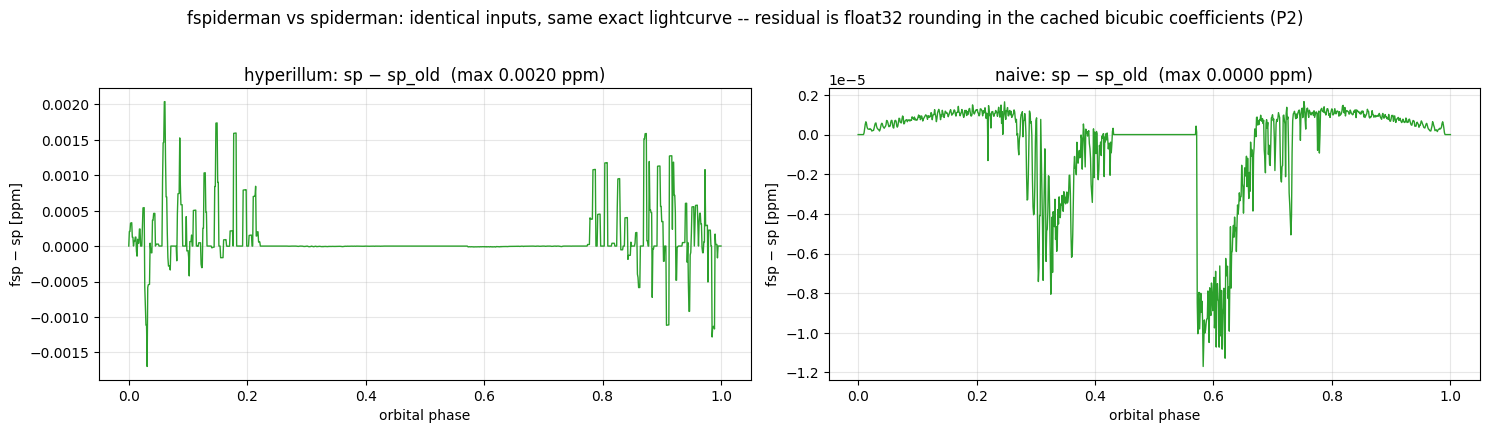

In [13]:
PAPER_MODE = False
# Build the thermal_PhaseCurve direct_T model with a given library and return its lightcurve [ppm]. Same inputs for sp_old and sp -> isolates the C patches.
# T_floor: the plain spiderman baseline (sp_old) has no bicubic clamp and exits on the negative overshoot below a 0 K nightside, so BOTH libraries get the same
# 100 K floor here (fspiderman itself needs none; the pipeline runs unfloored maps). The floor adds < 0.03 ppm at these wavelengths and cancels in the difference.
import tempfile
_comp_cache = {}
def _compensated_filter(path):
    """Temporary copy of a throughput file with T * lambda_um^2, the pre-compensation upstream spiderman's inverted get_filter factor needs (fspiderman fixed it, fork README patch 6)."""
    if path not in _comp_cache:
        w, T = np.loadtxt(path, unpack=True); tmp = tempfile.NamedTemporaryFile("w", suffix=".dat", delete=False)
        np.savetxt(tmp, np.c_[w, T * (w * 1e6) ** 2], fmt="%.10e %.10e"); tmp.close(); _comp_cache[path] = tmp.name
    return _comp_cache[path]

def lc_lib(lib, model, N_LAYERS=60, nt=1000, n_lo=200, n_la=100, T_floor=100., time_it=False):
    lo, la, Tg = custom_temperature_grid(planet, u_B=u_B, n_lo=n_lo, n_la=n_la, insolation_model=model, A_B=A_B)
    LO, LA = np.meshgrid(lo, la, indexing="ij")
    p = lib.ModelParams(brightness_model="direct_T", stellar_model="blackbody")
    p.n_layers = N_LAYERS; p.t0 = 0.; p.per = period; p.a_abs = a_AU
    p.inc, p.ecc, p.w = incl, ecc, w; p.rp, p.a = rp, a; p.p_u1 = p.p_u2 = 0.
    p.T_s = T_eff; p.l1, p.l2 = lambda_range
    p.grid = lib.format_grid(LO, LA, np.maximum(Tg, T_floor).T)
    fpath = filter_path if lib is sp else _compensated_filter(filter_path)   # sp_old: upstream get_filter divides by lambda instead of multiplying -> pre-multiply the file by lambda^2 so both libraries weight the band identically
    p.filter, p.eclipse = fpath, True
    with contextlib.redirect_stdout(io.StringIO()):
        sg = lib.stellar_grid.gen_grid(p.l1, p.l2, logg=4.5, response=fpath)
    t = np.linspace(0., period, nt)
    lc = (p.lightcurve(t, stellar_grid=sg) - 1) * 1e6
    if time_it:
        return lc, bench(lambda: p.lightcurve(t, stellar_grid=sg), repeats=1)
    return lc

# accuracy at a reference config (N_LAYERS=60, len(t)=1000), for both illumination models
tt = np.linspace(0., period, 1000)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for j, model in enumerate(("hyperillum", "naive")):
    lc_s, lc_f = lc_lib(sp_old, model), lc_lib(sp, model)
    d = lc_f - lc_s
    print(f"{model:6s} N_LAYERS=60, len(t)=1000:  max|Δ| = {np.abs(d).max():.5f} ppm,  rms = {np.sqrt((d**2).mean()):.5f} ppm")
    ax[j].plot(tt/period, d, color="C2", lw=1)
    ax[j].set_title(f"{model}: sp − sp_old  (max {np.abs(d).max():.4f} ppm)")
    ax[j].set_xlabel("orbital phase"); ax[j].set_ylabel("fsp − sp [ppm]"); ax[j].grid(alpha=.3)
fig.suptitle("fspiderman vs spiderman: identical inputs, same exact lightcurve -- "
             "residual is float32 rounding in the cached bicubic coefficients (P2)", y=1.02)
plt.tight_layout(); paper_figure("speed_fspiderman_vs_spiderman", PAPER_MODE); plt.show()

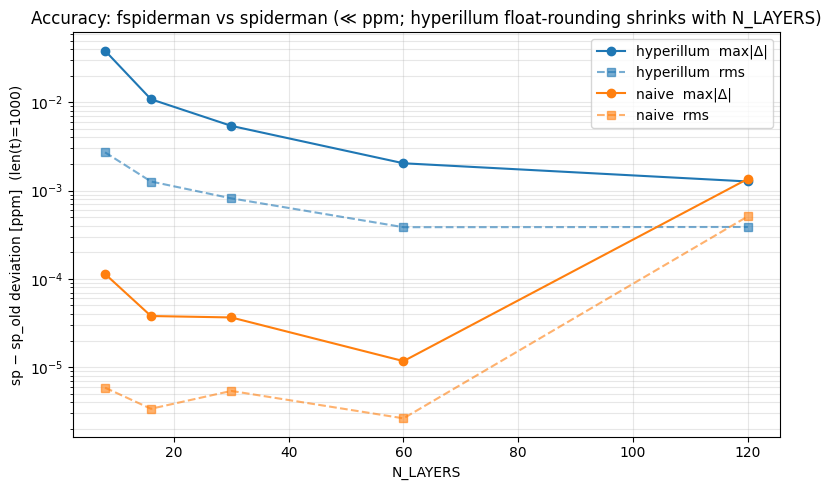

In [14]:
PAPER_MODE = False
# sp - sp_old deviation vs N_LAYERS (float rounding on the bicubic path; hyperillum has a sharp terminator, naive is ~identical)
NL_vals = [8, 16, 30, 60, 120]
dev = {}
for m in ("hyperillum", "naive"):
    rows = []
    for NL in NL_vals:
        d = np.abs(lc_lib(sp, m, N_LAYERS=NL) - lc_lib(sp_old, m, N_LAYERS=NL))
        rows.append((d.max(), np.sqrt((d ** 2).mean())))
    dev[m] = np.array(rows)

fig, ax = plt.subplots(figsize=(8, 5))
for m, c in (("hyperillum", "C0"), ("naive", "C1")):
    ax.plot(NL_vals, dev[m][:, 0], "o-",  color=c, label=f"{m}  max|Δ|")
    ax.plot(NL_vals, dev[m][:, 1], "s--", color=c, alpha=.6, label=f"{m}  rms")
ax.set_yscale("log")
ax.set_xlabel("N_LAYERS"); ax.set_ylabel("sp − sp_old deviation [ppm]  (len(t)=1000)")
ax.set_title("Accuracy: fspiderman vs spiderman (≪ ppm; hyperillum float-rounding shrinks with N_LAYERS)")
ax.grid(which="both", alpha=.3); ax.legend()
plt.tight_layout(); paper_figure("speed_fspiderman_accuracy_vs_nlayers", PAPER_MODE); plt.show()

  N_LAYERS=   8:  spiderman =     69.6 ms   fspiderman =     15.4 ms   speedup = 4.51x
  N_LAYERS=  16:  spiderman =    270.6 ms   fspiderman =     53.6 ms   speedup = 5.04x
  N_LAYERS=  30:  spiderman =    870.0 ms   fspiderman =    180.5 ms   speedup = 4.82x
  N_LAYERS=  60:  spiderman =   3147.3 ms   fspiderman =    681.3 ms   speedup = 4.62x
  N_LAYERS= 120:  spiderman =  11967.9 ms   fspiderman =   2693.5 ms   speedup = 4.44x


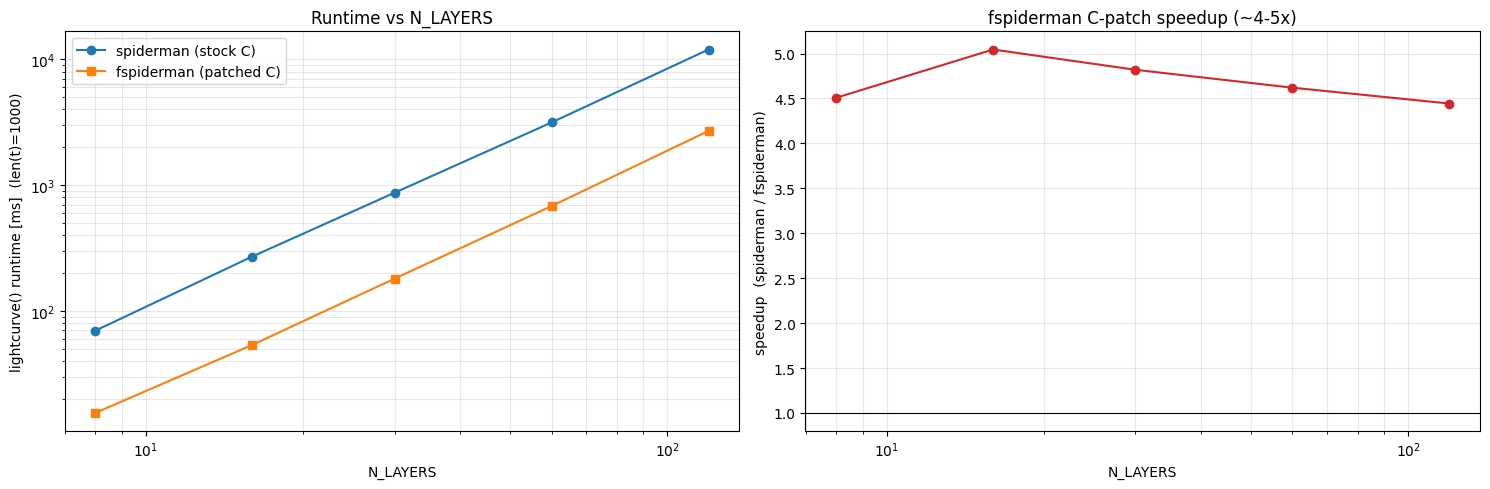

In [15]:
PAPER_MODE = False
# runtime: Stock spiderman vs fspiderman, exact lightcurve() vs N_LAYERS at len(t)=1000
NL_rt = [8, 16, 30, 60, 120]
t_s  = [lc_lib(sp_old,  "hyperillum", N_LAYERS=NL, time_it=True)[1] for NL in NL_rt]
t_f = [lc_lib(sp, "hyperillum", N_LAYERS=NL, time_it=True)[1] for NL in NL_rt]
for NL, s, f in zip(NL_rt, t_s, t_f):
    print(f"  N_LAYERS={NL:4d}:  spiderman = {s:8.1f} ms   fspiderman = {f:8.1f} ms   speedup = {s/f:.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].loglog(NL_rt, t_s,  "o-", label="spiderman (stock C)")
ax[0].loglog(NL_rt, t_f, "s-", label="fspiderman (patched C)")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("lightcurve() runtime [ms]  (len(t)=1000)")
ax[0].set_title("Runtime vs N_LAYERS"); ax[0].grid(which="both", alpha=.3); ax[0].legend()
ax[1].semilogx(NL_rt, np.array(t_s) / np.array(t_f), "o-", color="C3")
ax[1].axhline(1, color="k", lw=.8)
ax[1].set_xlabel("N_LAYERS"); ax[1].set_ylabel("speedup  (spiderman / fspiderman)")
ax[1].set_title("fspiderman C-patch speedup (~4-5x)"); ax[1].grid(which="both", alpha=.3)
plt.tight_layout(); paper_figure("speed_fspiderman_runtime", PAPER_MODE); plt.show()